Data shape: (15103, 32)
Columns: ['Age', 'Cholesterol', 'Creatinine', 'Diastolic', 'Glucose', 'Glycohemoglobin', 'HDL', 'LDH', 'Platelet Count', 'Red-Cell Distribution Width', 'Systolic', 'Triglycerides', 'Uric Acid', 'Gender_Female', 'Gender_Male', 'Vigorous Work_1.0', 'Vigorous Work_2.0', 'Vigorous Work_7.0', 'Moderate Work_1.0', 'Moderate Work_2.0', 'Moderate Work_7.0', 'Moderate Work_9.0', 'Diabetes_1.0', 'Diabetes_2.0', 'Diabetes_3.0', 'Diabetes_9.0', 'Blood-Rel Diabetes_1.0', 'Blood-Rel Diabetes_2.0', 'Blood-Rel Diabetes_9.0', 'Blood-Rel Stroke_No', 'Blood-Rel Stroke_Yes']

### Logistic Regression ###

Class order for Logistic Regression: ['diseased' 'normal']

===== Logistic Regression Test Results =====
Accuracy : 0.8982564555285809
Precision: 0.5087719298245614
Recall   : 0.06277056277056277
F1 Score : 0.11175337186897881
AUC      : 0.8211748315582181


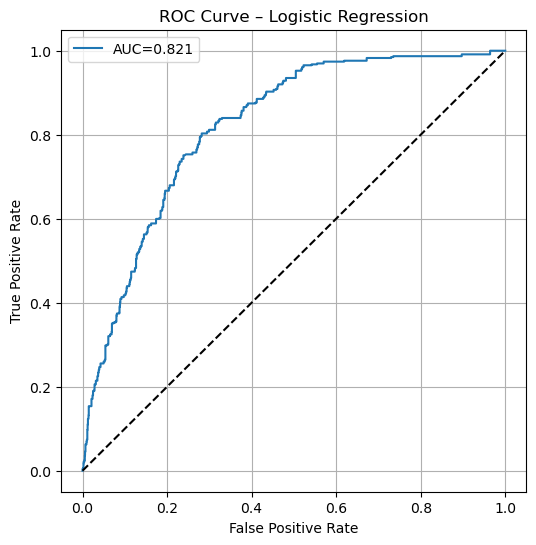

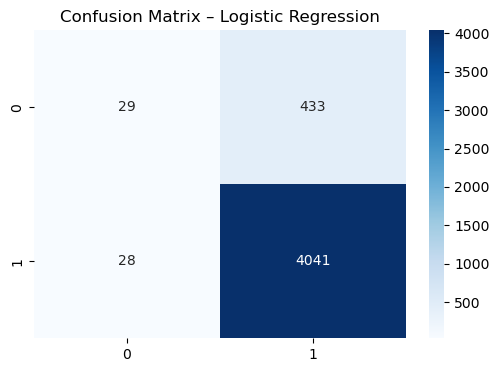


===== 5-Fold Cross-Validation – Logistic Regression =====
fit_time          2.782781
score_time        0.026802
test_accuracy     0.894911
test_precision    0.342183
test_recall       0.040460
test_f1           0.071847
dtype: float64
AUC (mean): 0.802556587669487


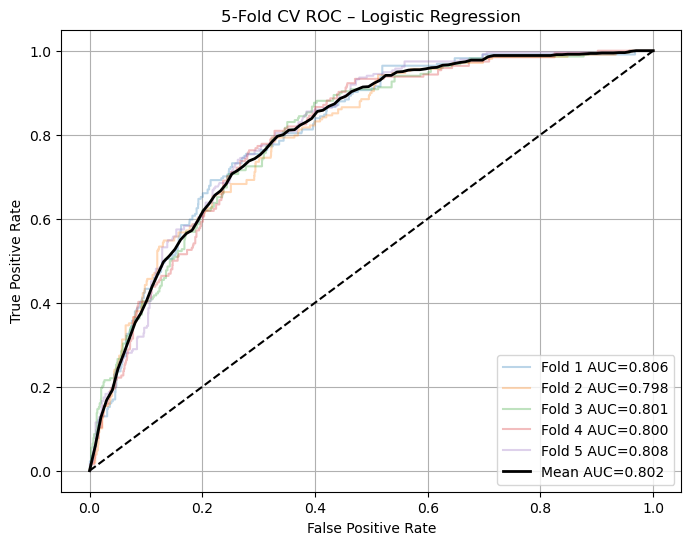


### Random Forest ###

Class order for Random Forest: ['diseased' 'normal']

===== Random Forest Test Results =====
Accuracy : 0.9944824542043699
Precision: 1.0
Recall   : 0.9458874458874459
F1 Score : 0.9721913236929922
AUC      : 0.9980182224591171


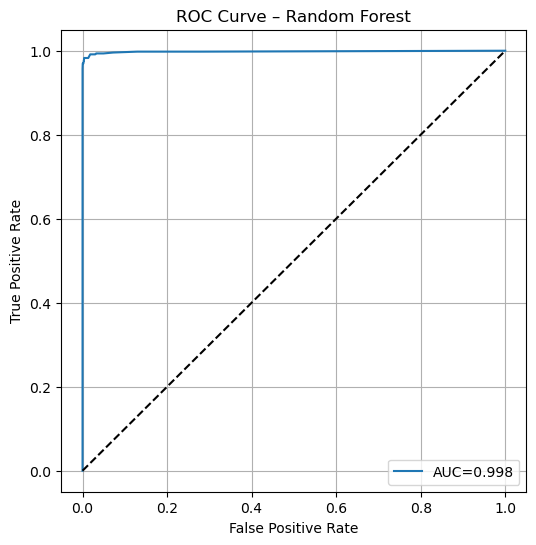

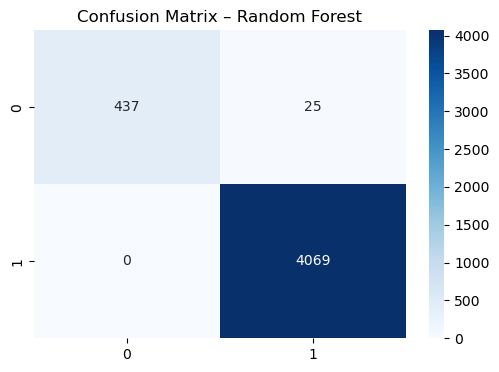


===== 5-Fold Cross-Validation – Random Forest =====
fit_time          0.107980
score_time        0.041344
test_accuracy     0.994514
test_precision    0.993835
test_recall       0.952185
test_f1           0.972485
dtype: float64
AUC (mean): 0.9935376800241607


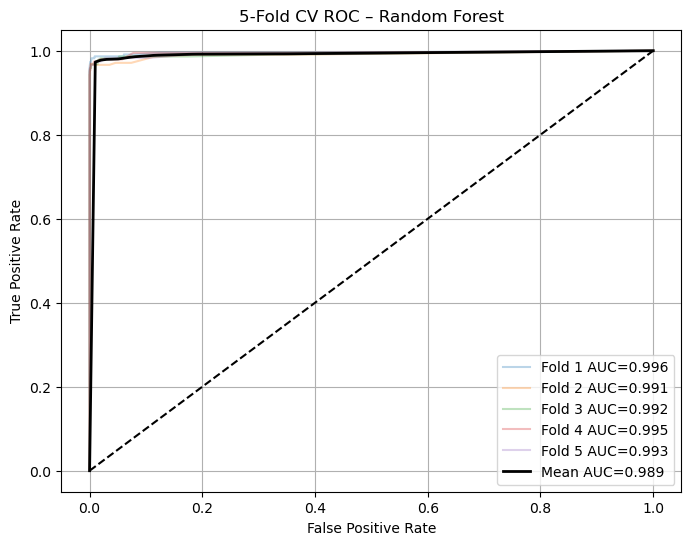


### KNN (k=3) ###

Class order for KNN (k=3): ['diseased' 'normal']

===== KNN (k=3) Test Results =====
Accuracy : 0.9796954314720813
Precision: 0.8806584362139918
Recall   : 0.9264069264069265
F1 Score : 0.9029535864978903
AUC      : 0.9866134930032693


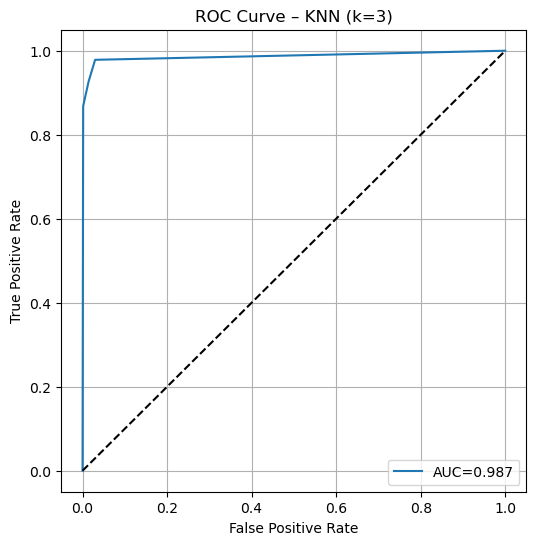

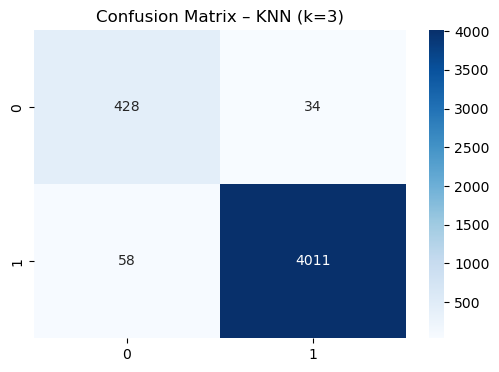


===== 5-Fold Cross-Validation – KNN (k=3) =====
fit_time          0.007553
score_time        0.090629
test_accuracy     0.974271
test_precision    0.860930
test_recall       0.891144
test_f1           0.875090
dtype: float64
AUC (mean): 0.978208565688074


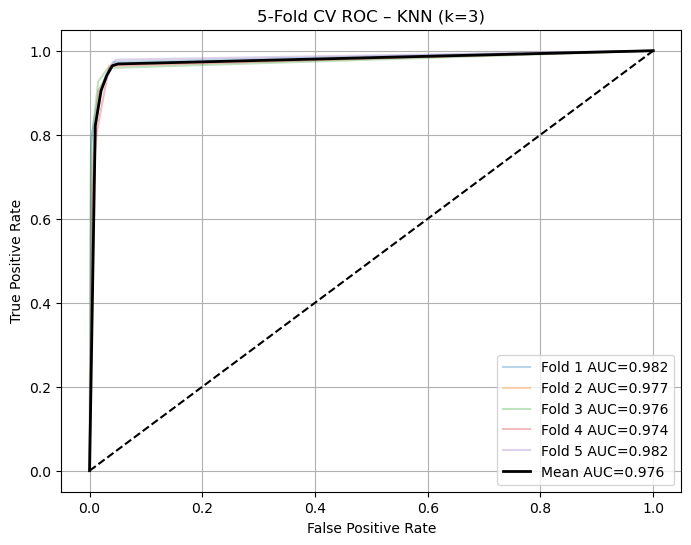

In [2]:
# ==============================================================
# IMPORTS
# ==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, confusion_matrix, make_scorer
)

# ==============================================================
# 1. LOAD DATA
# ==============================================================

df = pd.read_csv("heart_disease_preprocessed.csv")

X = df.drop(columns=["disease_status"])
y = df["disease_status"]

print("Data shape:", df.shape)
print("Columns:", X.columns.tolist())

# ==============================================================
# 2. TRAIN/TEST SPLIT
# ==============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

# ==============================================================
# HELPER — get correct probability column
# ==============================================================

def get_probabilities(model, X):
    """Ensure we always take the probability for class 'diseased'."""
    classes = list(model.classes_)
    target_index = classes.index("diseased")     # find correct column
    return model.predict_proba(X)[:, target_index]


# ==============================================================
# 3. TEST EVALUATION FUNCTION
# ==============================================================

def evaluate_model(model, model_name):

    model.fit(X_train, y_train)
    print(f"\nClass order for {model_name}: {model.classes_}")

    # Correct probability extraction
    probs = get_probabilities(model, X_test)
    preds = model.predict(X_test)

    # Metrics
    acc  = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, pos_label="diseased")
    rec  = recall_score(y_test, preds, pos_label="diseased")
    f1   = f1_score(y_test, preds, pos_label="diseased")

    fpr, tpr, _ = roc_curve(y_test, probs, pos_label="diseased")
    auc_val = auc(fpr, tpr)

    print(f"\n===== {model_name} Test Results =====")
    print("Accuracy :", acc)
    print("Precision:", prec)
    print("Recall   :", rec)
    print("F1 Score :", f1)
    print("AUC      :", auc_val)

    # ROC Curve
    plt.figure(figsize=(6,6))
    plt.plot(fpr, tpr, label=f"AUC={auc_val:.3f}")
    plt.plot([0,1], [0,1], "k--")
    plt.title(f"ROC Curve – {model_name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.grid()
    plt.legend()
    plt.show()

    # Confusion Matrix
    cm = confusion_matrix(y_test, preds, labels=["diseased", "normal"])
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix – {model_name}")
    plt.show()

    return model


# ==============================================================
# 4. 5-FOLD CROSS-VALIDATION RESULTS (METRICS + AUC)
# ==============================================================

def cross_validate_model(model, model_name):

    scoring = {
        "accuracy": make_scorer(accuracy_score),
        "precision": make_scorer(precision_score, pos_label="diseased"),
        "recall": make_scorer(recall_score, pos_label="diseased"),
        "f1": make_scorer(f1_score, pos_label="diseased")
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    cv_results = cross_validate(
        model, X_train, y_train, cv=kf,
        scoring=scoring, return_train_score=False
    )

    # Compute AUC for each fold
    aucs = []
    for train_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        model.fit(X_tr, y_tr)
        probs = get_probabilities(model, X_val)

        fpr, tpr, _ = roc_curve(y_val, probs, pos_label="diseased")
        aucs.append(auc(fpr, tpr))

    print(f"\n===== 5-Fold Cross-Validation – {model_name} =====")
    print(pd.DataFrame(cv_results).mean())
    print("AUC (mean):", np.mean(aucs))

    return aucs


# ==============================================================
# 5. 5-FOLD ROC PLOT
# ==============================================================

def plot_cv_roc(model, model_name):

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    mean_fpr = np.linspace(0, 1, 100)
    tprs, aucs = [], []

    plt.figure(figsize=(8,6))

    for i, (train_idx, val_idx) in enumerate(kf.split(X_train)):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        model.fit(X_tr, y_tr)
        probs = get_probabilities(model, X_val)

        fpr, tpr, _ = roc_curve(y_val, probs, pos_label="diseased")
        fold_auc = auc(fpr, tpr)
        aucs.append(fold_auc)

        plt.plot(fpr, tpr, alpha=0.3, label=f"Fold {i+1} AUC={fold_auc:.3f}")

        # interpolate for mean curve
        tpr_interp = np.interp(mean_fpr, fpr, tpr)
        tpr_interp[0] = 0.0
        tprs.append(tpr_interp)

    # Mean ROC curve
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)

    plt.plot(mean_fpr, mean_tpr, color="black", linewidth=2,
             label=f"Mean AUC={mean_auc:.3f}")

    plt.plot([0,1],[0,1],"k--")
    plt.title(f"5-Fold CV ROC – {model_name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid()
    plt.show()


# ==============================================================
# BASELINE MODEL RUNS
# ==============================================================

print("\n### Logistic Regression ###")
lr_model = LogisticRegression(
    penalty="l2", solver="saga", max_iter=5000, n_jobs=-1
)
evaluate_model(lr_model, "Logistic Regression")
cross_validate_model(lr_model, "Logistic Regression")
plot_cv_roc(lr_model, "Logistic Regression")


print("\n### Random Forest ###")
rf_model = RandomForestClassifier(
    n_estimators=50, random_state=42, n_jobs=-1
)
evaluate_model(rf_model, "Random Forest")
cross_validate_model(rf_model, "Random Forest")
plot_cv_roc(rf_model, "Random Forest")


print("\n### KNN (k=3) ###")
knn_model = KNeighborsClassifier(
    n_neighbors=3, metric="euclidean"
)
evaluate_model(knn_model, "KNN (k=3)")
cross_validate_model(knn_model, "KNN (k=3)")
plot_cv_roc(knn_model, "KNN (k=3)")


In [3]:
import numpy as np
import pandas as pd

def lr_feature_importance(model, feature_names, top_n=15):
    # model must be fitted
    coefs = model.coef_.ravel()
    odds_ratio = np.exp(coefs)

    out = pd.DataFrame({
        "feature": feature_names,
        "coef": coefs,
        "odds_ratio": odds_ratio,
        "abs_coef": np.abs(coefs)
    }).sort_values("abs_coef", ascending=False)

    return out.head(top_n)

# after you run evaluate_model(lr_model, ...)
lr_imp = lr_feature_importance(lr_model, X.columns, top_n=20)
print(lr_imp)


                        feature      coef  odds_ratio  abs_coef
21            Moderate Work_9.0 -1.377120    0.252304  1.377120
19            Moderate Work_2.0  0.928608    2.530982  0.928608
0                           Age -0.900384    0.406414  0.900384
18            Moderate Work_1.0  0.795557    2.215675  0.795557
29          Blood-Rel Stroke_No  0.590286    1.804504  0.590286
28       Blood-Rel Diabetes_9.0  0.504528    1.656203  0.504528
13                Gender_Female  0.394966    1.484334  0.394966
1                   Cholesterol  0.351565    1.421290  0.351565
24                 Diabetes_3.0  0.348221    1.416545  0.348221
5               Glycohemoglobin -0.222081    0.800850  0.222081
30         Blood-Rel Stroke_Yes -0.194120    0.823559  0.194120
15            Vigorous Work_1.0  0.175339    1.191650  0.175339
16            Vigorous Work_2.0  0.171705    1.187328  0.171705
12                    Uric Acid -0.163283    0.849351  0.163283
7                           LDH -0.15983

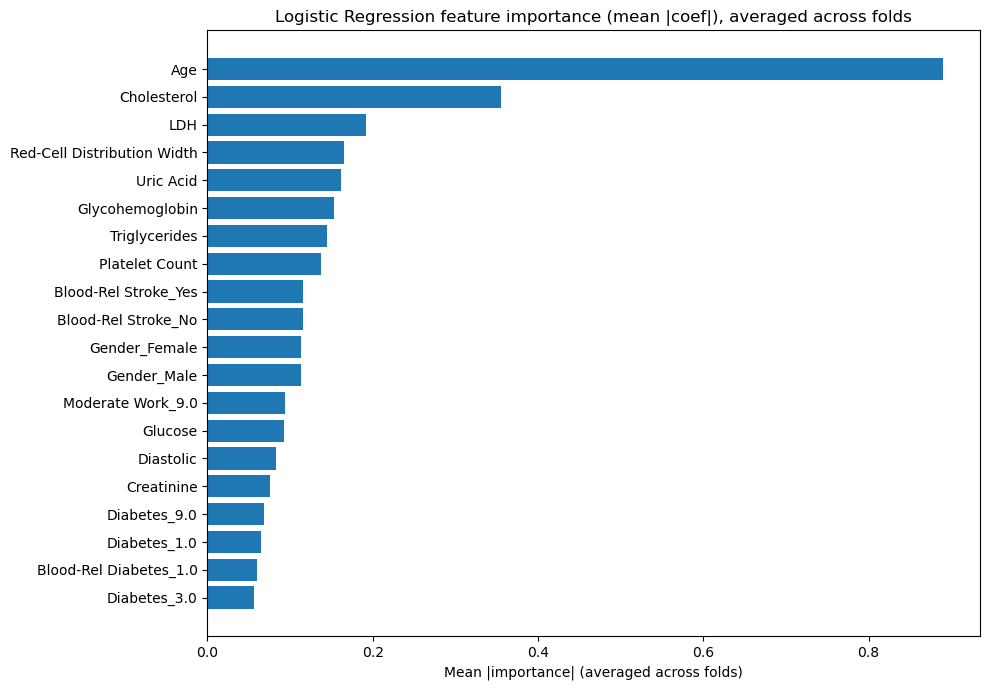

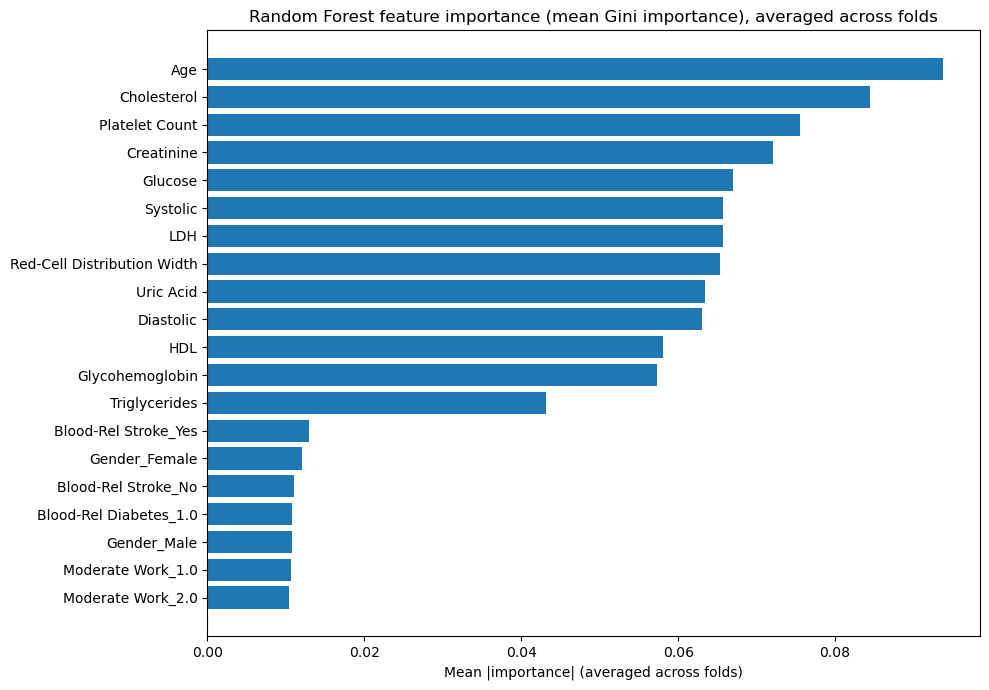

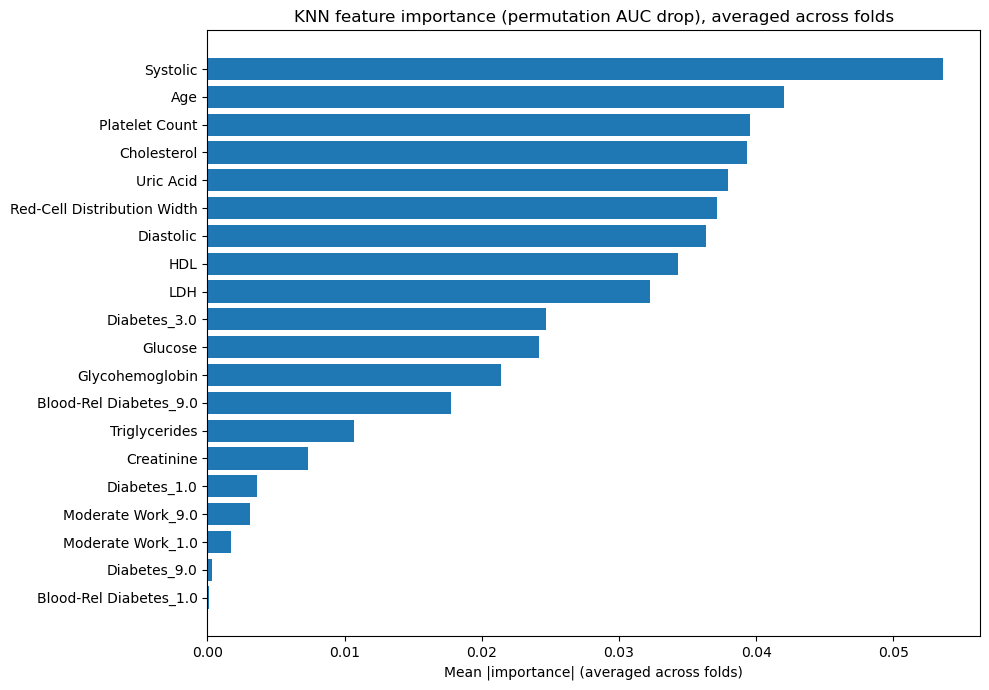

,feature,importance
0,Systolic,0.053637
1,Age,0.042010
2,Platelet Count,0.039518
3,Cholesterol,0.039325
4,Uric Acid,0.037961
5,Red-Cell Distribution Width,0.037180
6,Diastolic,0.036370
7,HDL,0.034306
8,LDH,0.032263
9,Diabetes_3.0,0.024693


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance

# =========================
# 1) LOAD DATA
# =========================
df = pd.read_csv("heart_disease_preprocessed.csv")
X = df.drop(columns=["disease_status"])
y = df["disease_status"]

# Make positive class consistent (important!)
# diseased = 1, normal = 0
y_bin = (y == "diseased").astype(int)

feature_names = X.columns.to_list()

# =========================
# 2) MODELS
# =========================
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(penalty="l2", solver="saga", max_iter=5000, n_jobs=-1, random_state=42))
])

rf = RandomForestClassifier(
    n_estimators=50, random_state=42, n_jobs=-1
)

knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=3, metric="euclidean"))
])

# =========================
# 3) HELPERS
# =========================
def plot_importance(mean_imp, feature_names, title, top_k=20, save_path=None):
    mean_imp = np.asarray(mean_imp)

    order = np.argsort(mean_imp)[::-1][:top_k]
    top_feats = np.array(feature_names)[order][::-1]
    top_vals = mean_imp[order][::-1]

    plt.figure(figsize=(10, 7))
    plt.barh(top_feats, top_vals)
    plt.xlabel("Mean |importance| (averaged across folds)")
    plt.title(title)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    return pd.DataFrame({"feature": np.array(feature_names)[order], "importance": mean_imp[order]})


def cv_importance_logistic(lr_pipeline, X, y_bin, n_splits=5):
    """Mean abs standardized coefficients across folds."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    imps = []

    for tr_idx, va_idx in skf.split(X, y_bin):
        X_tr, y_tr = X.iloc[tr_idx], y_bin.iloc[tr_idx]
        lr_pipeline.fit(X_tr, y_tr)

        coef = lr_pipeline.named_steps["lr"].coef_.ravel()  # shape (n_features,)
        imps.append(np.abs(coef))

    return np.mean(np.vstack(imps), axis=0)


def cv_importance_rf(rf_model, X, y_bin, n_splits=5):
    """Mean feature_importances_ across folds."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    imps = []

    for tr_idx, va_idx in skf.split(X, y_bin):
        X_tr, y_tr = X.iloc[tr_idx], y_bin.iloc[tr_idx]
        rf_model.fit(X_tr, y_tr)
        imps.append(rf_model.feature_importances_)

    return np.mean(np.vstack(imps), axis=0)


def cv_importance_permutation(model, X, y_bin, n_splits=5, n_repeats=10):
    """
    Model-agnostic permutation importance (AUC drop) averaged across folds.
    Works for KNN and also can be used for LR/RF if you want consistency.
    """
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    imps = []

    for tr_idx, va_idx in skf.split(X, y_bin):
        X_tr, y_tr = X.iloc[tr_idx], y_bin.iloc[tr_idx]
        X_va, y_va = X.iloc[va_idx], y_bin.iloc[va_idx]

        model.fit(X_tr, y_tr)

        r = permutation_importance(
            model, X_va, y_va,
            scoring="roc_auc",
            n_repeats=n_repeats,
            random_state=42,
            n_jobs=-1
        )
        imps.append(r.importances_mean)

    return np.mean(np.vstack(imps), axis=0)

# =========================
# 4) COMPUTE + PLOT
# =========================

# Logistic Regression: |coefficients|
lr_imp = cv_importance_logistic(lr, X, y_bin, n_splits=5)
plot_importance(lr_imp, feature_names,
                title="Logistic Regression feature importance (mean |coef|), averaged across folds",
                top_k=20, save_path="lr_importance.png")

# Random Forest: Gini importance
rf_imp = cv_importance_rf(rf, X, y_bin, n_splits=5)
plot_importance(rf_imp, feature_names,
                title="Random Forest feature importance (mean Gini importance), averaged across folds",
                top_k=20, save_path="rf_importance.png")

# KNN: permutation importance (AUC drop)
knn_imp = cv_importance_permutation(knn, X, y_bin, n_splits=5, n_repeats=10)
plot_importance(knn_imp, feature_names,
                title="KNN feature importance (permutation AUC drop), averaged across folds",
                top_k=20, save_path="knn_importance.png")
